# ¡Llena ese carrito!

# Introducción

Instacart es una plataforma de entregas de comestibles donde la clientela puede registrar un pedido y hacer que se lo entreguen, similar a Uber Eats y Door Dash.
El conjunto de datos que te hemos proporcionado tiene modificaciones del original. Redujimos el tamaño del conjunto para que tus cálculos se hicieran más rápido e introdujimos valores ausentes y duplicados. Tuvimos cuidado de conservar las distribuciones de los datos originales cuando hicimos los cambios.

Debes completar tres pasos. Para cada uno de ellos, escribe una breve introducción que refleje con claridad cómo pretendes resolver cada paso, y escribe párrafos explicatorios que justifiquen tus decisiones al tiempo que avanzas en tu solución.  También escribe una conclusión que resuma tus hallazgos y elecciones.

## Diccionario de datos

Hay cinco tablas en el conjunto de datos, y tendrás que usarlas todas para hacer el preprocesamiento de datos y el análisis exploratorio de datos. A continuación se muestra un diccionario de datos que enumera las columnas de cada tabla y describe los datos que contienen.

- `instacart_orders.csv`: cada fila corresponde a un pedido en la aplicación Instacart.
    - `'order_id'`: número de ID que identifica de manera única cada pedido.
    - `'user_id'`: número de ID que identifica de manera única la cuenta de cada cliente.
    - `'order_number'`: el número de veces que este cliente ha hecho un pedido.
    - `'order_dow'`: día de la semana en que se hizo el pedido (0 si es domingo).
    - `'order_hour_of_day'`: hora del día en que se hizo el pedido.
    - `'days_since_prior_order'`: número de días transcurridos desde que este cliente hizo su pedido anterior.
- `products.csv`: cada fila corresponde a un producto único que pueden comprar los clientes.
    - `'product_id'`: número ID que identifica de manera única cada producto.
    - `'product_name'`: nombre del producto.
    - `'aisle_id'`: número ID que identifica de manera única cada categoría de pasillo de víveres.
    - `'department_id'`: número ID que identifica de manera única cada departamento de víveres.
- `order_products.csv`: cada fila corresponde a un artículo pedido en un pedido.
    - `'order_id'`: número de ID que identifica de manera única cada pedido.
    - `'product_id'`: número ID que identifica de manera única cada producto.
    - `'add_to_cart_order'`: el orden secuencial en el que se añadió cada artículo en el carrito.
    - `'reordered'`: 0 si el cliente nunca ha pedido este producto antes, 1 si lo ha pedido.
- `aisles.csv`
    - `'aisle_id'`: número ID que identifica de manera única cada categoría de pasillo de víveres.
    - `'aisle'`: nombre del pasillo.
- `departments.csv`
    - `'department_id'`: número ID que identifica de manera única cada departamento de víveres.
    - `'department'`: nombre del departamento.

# Paso 1. Descripción de los datos

Lee los archivos de datos (`data/instacart_orders.csv`, `data/products.csv`, `data/aisles.csv`, `data/departments.csv` y `data/order_products.csv`) con `pd.read_csv()` usando los parámetros adecuados para leer los datos correctamente. Verifica la información para cada DataFrame creado.

## Plan de solución


1. Importo las librerias
2. Obtengo los dataframes a partir de los csv con el metodo read_csv() teniendo claro el separador que en este caso es ';'
3. Obtengo el detalle de cada dataframe con el método info()
4. Obtengo una muestra de cada dataframe con los métodos head(), tail() o sample()

In [1]:
# importar librerías
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# leectura de los conjuntos de datos en los DataFrames de pandas
df_instacart_orders = pd.read_csv('data/instacart_orders.csv', sep=';')
df_products = pd.read_csv('data/products.csv', sep=';')
df_aisles = pd.read_csv('data/aisles.csv', sep=';')
df_departments = pd.read_csv('data/departments.csv', sep=';')
df_order_products = pd.read_csv('data/order_products.csv.gz', sep=';')

In [3]:
# Información y muestra del DataFrame df_instacart_orders
df_instacart_orders.info()
print("")
df_instacart_orders.head()

<class 'pandas.DataFrame'>
RangeIndex: 478967 entries, 0 to 478966
Data columns (total 6 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   order_id                478967 non-null  int64  
 1   user_id                 478967 non-null  int64  
 2   order_number            478967 non-null  int64  
 3   order_dow               478967 non-null  int64  
 4   order_hour_of_day       478967 non-null  int64  
 5   days_since_prior_order  450148 non-null  float64
dtypes: float64(1), int64(5)
memory usage: 21.9 MB



,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,1515936,183418,11,6,13,30.0
1,1690866,163593,5,5,12,9.0
2,1454967,39980,4,5,19,2.0
3,1768857,82516,56,0,20,10.0
4,3007858,196724,2,4,12,17.0


In [4]:
# Información y muestra del DataFrame df_products
df_products.info()
print("")
df_products.sample(n=5)

<class 'pandas.DataFrame'>
RangeIndex: 49694 entries, 0 to 49693
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   product_id     49694 non-null  int64
 1   product_name   48436 non-null  str  
 2   aisle_id       49694 non-null  int64
 3   department_id  49694 non-null  int64
dtypes: int64(3), str(1)
memory usage: 1.5 MB



,product_id,product_name,aisle_id,department_id
38460,38461,Chicken Fried Chicken Meal,38,1
31845,31846,Heavy Whip Cream,53,16
40014,40015,Best Grillin Steakhouse Recipe Beans,59,15
44293,44294,Seriously Sharp Cheddar,21,16
22612,22613,Organic African Nectar Herbal Tea,94,7


In [5]:
# Información y muestra del DataFrame df_aisles
df_aisles.info()
print("")
df_aisles.head()

<class 'pandas.DataFrame'>
RangeIndex: 134 entries, 0 to 133
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   aisle_id  134 non-null    int64
 1   aisle     134 non-null    str  
dtypes: int64(1), str(1)
memory usage: 2.2 KB



,aisle_id,aisle
0,1,prepared soups salads
1,2,specialty cheeses
2,3,energy granola bars
3,4,instant foods
4,5,marinades meat preparation


In [6]:
# Información y muestra del DataFrame df_departments
df_departments.info()
print("")
df_departments.tail()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   department_id  21 non-null     int64
 1   department     21 non-null     str  
dtypes: int64(1), str(1)
memory usage: 468.0 bytes



,department_id,department
16,17,household
17,18,babies
18,19,snacks
19,20,deli
20,21,missing


In [7]:
# Información y muestra del DataFrame df_order_products
df_order_products.info(show_counts=True)
print("")
df_order_products.head()

<class 'pandas.DataFrame'>
RangeIndex: 4545007 entries, 0 to 4545006
Data columns (total 4 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   order_id           4545007 non-null  int64  
 1   product_id         4545007 non-null  int64  
 2   add_to_cart_order  4544171 non-null  float64
 3   reordered          4545007 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 138.7 MB



,order_id,product_id,add_to_cart_order,reordered
0,2141543,11440,17.0,0
1,567889,1560,1.0,1
2,2261212,26683,1.0,1
3,491251,8670,35.0,1
4,2571142,1940,5.0,1


## Conclusiones


- El dataframe con mayor volumen de datos es **`df_order_products`** debido a que tiene **4.545.007** y contiene valores ausentes en la columna **`add_to_cart_order`**, por lo tanto, hay que realizar una limpieza o reasignación de dichos registros en ese campo. Por otro lado, todas las columnas poseen datos cuantitativos. Por ultimo, los tipos de datos de cada columna son correctos, pero vale la pena revisar el campo **`add_to_cart_order`** el cual deberia ser un int.
  
- El dataframe **`df_departments`** es el de menor volumen de datos y tiene tan solo **21** registros. No contiene valores ausentes y los tipos de datos corresponden al contenido, sin embargo habria que revisar el campo **`department`** si hay algun caracter especial.
  
- El dataframe **`df_aisles`** posee tan solo **134** registros, no posee valores ausentes y los tipos de datos corresponden al contenido. Sin embargo habria que revisar el campo **`aisle`** si hay algún caracter especial.
  
- El dataframe **`df_products`** posee una volumetria de **49.694** registros y posee valores ausentes en el campo **`product_name`** de igual manera hay que revisar si hay algun caracter especial para revisar el tipo de dato object en ese mismo campo.
  
- El dataframe **`df_instacart_orders`** posee **478.967** registros de los cuales hay valores ausentes en la columna **`days_since_prior_order`**, se observa que los tipos de datos concuerdan con lo que contiene en la muestra de datos.

# Paso 2. Preprocesamiento de los datos

Preprocesa los datos de la siguiente manera:
- Verifica y corrige los tipos de datos (por ejemplo, asegúrate de que las columnas de ID sean números enteros).
- Identifica y completa los valores ausentes.
- Identifica y elimina los valores duplicados.

Asegúrate de explicar qué tipos de valores ausentes y duplicados encontraste, cómo los completaste o eliminaste y por qué usaste esos métodos. ¿Por qué crees que estos valores ausentes y duplicados pueden haber estado presentes en el conjunto de datos?

## Plan de solución

Escribe aquí tu plan para el Paso 2. Preprocesamiento de los datos.

1. Revisar para cada dataframe si hay duplicados con el metodo duplicated()
2. Revisar tipos de datos en los dataframes y columnas referenciadas en el punto 1.
3. Corregir los tipos de datos segun sea el caso
4. Revisar el tipo de valores ausentes y reemplazarlos segun sea el caso

## Encuentra y elimina los valores duplicados (y describe cómo tomaste tus decisiones).

### `orders` data frame

In [8]:
# Revisa si hay pedidos duplicados

# Filtro el dataframe por los duplicados y lo ordeno en función de los ids para que se evidecie las filas repetidas
dup_instacart = df_instacart_orders[df_instacart_orders.duplicated(keep=False)].sort_values(['order_id', 'user_id']) 
dup_instacart


,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
354993,391768,57671,19,3,2,10.0
371905,391768,57671,19,3,2,10.0
119251,408114,68324,4,3,2,18.0
321100,408114,68324,4,3,2,18.0
250626,467134,63189,21,3,2,2.0
394347,467134,63189,21,3,2,2.0
99462,794638,50898,24,3,2,2.0
145574,794638,50898,24,3,2,2.0
242618,1021560,53767,3,3,2,9.0
311713,1021560,53767,3,3,2,9.0


In [9]:
print(f"Registros duplicados + Original: {len(dup_instacart)}") # Cantidad de registros duplicados con sus repetidos
print(f"Registros duplicados: {df_instacart_orders.duplicated().sum()}") # Cantidad de registros duplicados

Registros duplicados + Original: 30


Registros duplicados: 15


¿Tienes líneas duplicadas? Si sí, ¿qué tienen en común?

Si hay líneas/registros duplicadas y son identicas en todas las columnas/campos, es decir, poseen el mismo valor desde la columna "order_id" hasta la columna "days_since_prior_order"

In [10]:
# Basándote en tus hallazgos,
# Verifica todos los pedidos que se hicieron el miércoles a las 2:00 a.m.

# Los días son 0:Domingo, 1:Lunes, 2:Martes, 3:Miercoles entonces:
order_wed_2 = df_instacart_orders.query("order_hour_of_day == 2 and order_dow == 3")
order_wed_2

,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
4838,2766110,162084,41,3,2,16.0
5156,2190225,138285,18,3,2,11.0
15506,553049,58599,13,3,2,7.0
18420,382357,120200,19,3,2,11.0
24691,690242,77357,2,3,2,9.0
...,...,...,...,...,...,...
457013,3384021,14881,6,3,2,30.0
458816,910166,164782,18,3,2,4.0
459635,1680532,106435,6,3,2,21.0
468324,222962,54979,59,3,2,3.0


In [11]:
print(f"Cantidad de ordenes hechas el miercoles a las 2:00a .m.: {len(order_wed_2)}")

Cantidad de ordenes hechas el miercoles a las 2:00a .m.: 121


¿Qué sugiere este resultado?

El resultado muestra que en total hay 121 registros que corresponden a las órdenes del miércoles a las 2:00 a.m., adicionalmente se identificaron 15 duplicados. Por lo tanto, al aplicar la eliminación de duplicados, el total neto deberia ser de 106 registros.

In [12]:
# Elimina los pedidos duplicados

# Aplico el metodo drop_duplicates y reincio los indices del dataframe
df_instacart_orders = df_instacart_orders.drop_duplicates().reset_index(drop=True)

In [13]:
# Vuelve a verificar si hay filas duplicadas

# Aplico el metodo duplicated junto con sum() para obtener el valor de filas duplicadas
print(f"Cantidad de registros duplicados de ordenes: {df_instacart_orders.duplicated().sum()}")

Cantidad de registros duplicados de ordenes: 0


In [14]:
# Vuelve a verificar únicamente si hay IDs duplicados de pedidos

print(f"Cantidad de IDs duplicados de pedidos: {df_instacart_orders['order_id'].duplicated().sum()}")
print(f"Cantidad neta de registros sin duplicados: {df_instacart_orders['order_id'].nunique()}")

Cantidad de IDs duplicados de pedidos: 0
Cantidad neta de registros sin duplicados: 478952


### Describe brevemente tus hallazgos y lo que hiciste con ellos

Al aplicar el método "drop_duplicates()" se eliminaron **15 filas** por ser duplicados idénticos. Es decir, en un inicio este dataframe contenía **478.967 filas** y al quitarle **15 duplicadas** se tiene un total neto de **478.952**. Finalmente, la verificación de la ausencia IDs duplicados confirma el resultado exitoso de la operación de borrado.

### `products` data frame

In [15]:
# Verifica si hay filas totalmente duplicadas

# Cantidad de filas duplicadas
print(f"Cantidad de productos Duplicados: {df_products.duplicated().sum()}")

Cantidad de productos Duplicados: 0


In [16]:
# Revisa únicamente si hay ID de productos duplicados

# Cantidad de IDs duplicados
print(f"Cantidad de IDs duplicados en productos: {df_products['product_id'].duplicated().sum()}")

Cantidad de IDs duplicados en productos: 0


In [17]:
# Revisa únicamente si hay nombres duplicados de productos (convierte los nombres a letras mayúsculas para compararlos mejor)

# conversion a mayusculas de toda la columna "product_name" y obtención de duplicados sobre la columna product_name
print(f"Cantidad productos duplicados con nombres en mayuscula: {df_products['product_name'].str.upper().duplicated().sum()}")

Cantidad productos duplicados con nombres en mayuscula: 1361


In [18]:
# Revisa si hay nombres duplicados de productos no faltantes

# Obtengo los datos sin valores ausentes
df_prod_not_na = df_products[df_products['product_name'].notna()]

# Obtengo los datos que son valores ausentes
df_prod_is_na = df_products[df_products['product_name'].isna()]

# Cantidad de registros para cada caso
print(f"Cantidad de filas de productos sin valores ausentes: {len(df_prod_not_na)}")
print(f"Cantidad de filas de productos con valores ausentes: {len(df_prod_is_na)}")

# Analisis de valores ausentes con nombres de productos sin transformacion
print(f"Cantidad de nombres duplicados sin valores ausentes sin transformarlos a mayusculas: {df_prod_not_na['product_name'].duplicated().sum()}")

# Adicionalmente se realiza un analisis transformando los nombres de los productos a mayusculas
print(f"Cantidad de nombres duplicados sin valores ausentes transformandolos a mayusculas: {df_prod_not_na['product_name'].str.upper().duplicated().sum()}")
print(f"Cantidad de nombres duplicados con valores ausentes transformandolos a mayusculas: {df_products['product_name'].str.upper().duplicated().sum()}")

Cantidad de filas de productos sin valores ausentes: 48436
Cantidad de filas de productos con valores ausentes: 1258
Cantidad de nombres duplicados sin valores ausentes sin transformarlos a mayusculas: 0
Cantidad de nombres duplicados sin valores ausentes transformandolos a mayusculas: 104
Cantidad de nombres duplicados con valores ausentes transformandolos a mayusculas: 1361


In [19]:
# Detalle de movimientos duplicados por nombre del producto en mayuscula
df_products['product_name_upper'] = df_products['product_name'].str.upper()
df_products[df_products['product_name_upper'].duplicated(keep=False)].sort_values(by='product_name_upper')

,product_id,product_name,aisle_id,department_id,product_name_upper
23339,23340,18-in-1 Hemp Peppermint Pure-Castile Soap,25,11,18-IN-1 HEMP PEPPERMINT PURE-CASTILE SOAP
31844,31845,18-In-1 Hemp Peppermint Pure-Castile Soap,25,11,18-IN-1 HEMP PEPPERMINT PURE-CASTILE SOAP
19941,19942,Aged Balsamic Vinegar Of Modena,19,13,AGED BALSAMIC VINEGAR OF MODENA
13152,13153,Aged Balsamic Vinegar of Modena,19,13,AGED BALSAMIC VINEGAR OF MODENA
24830,24831,Albacore Solid White Tuna in Water,95,15,ALBACORE SOLID WHITE TUNA IN WATER
...,...,...,...,...,...
49552,49553,NaN,100,21,NaN
49574,49575,NaN,100,21,NaN
49640,49641,NaN,100,21,NaN
49663,49664,NaN,100,21,NaN


Tras los preprocesamientos iniciales, se confirmó la ausencia de registros duplicados a nivel de fila completa y de identificadores en la columna `product_id`. En consecuencia, el análisis se centró en la columna `product_name`, bajo la hipótesis de que este campo podría contener inconsistencias tipográficas, valores nulos o duplicados semánticos.

1. Identificación de duplicados y valores nulos
Como paso inicial, se normalizaron los nombres a mayúsculas. El método *duplicated().sum()* detectó inicialmente **1.361** registros duplicados. Al segmentar el set de datos, se identificaron **1.258** valores ausentes y **48.436** registros válidos. Al reevaluar este último grupo, se detectaron **104** nombres duplicados reales, lo que arroja un total neto de **48.332** nombres únicos. Esto confirma que la gran mayoría de las repeticiones iniciales correspondían a valores nulos.

2. Estrategia de consolidación e integridad
Al inspeccionar los duplicados en `product_name`, se observó que algunos comparten el mismo `aisle_id` y `department_id`, sugiriendo errores de captura para un mismo producto. Antes de proceder con la eliminación, es recomendable hacer una consolidación de filas para preservar la distribución de los demás campos. Asimismo, es importante evaluar si los registros con nombres ausentes poseen datos relevantes en otras columnas que justifiquen su imputación.

3. Impacto en la integración de datos (Merge)
Es crucial señalar que cualquier eliminación de duplicados en `df_products` debe coordinarse con el dataframe `df_order_products`. Si se elimina un `product_id` sin actualizar sus referencias en la tabla de pedidos, se perdería información crítica sobre las compras de los clientes. Por consiguiente, se decide NO eliminar los registros duplicados en `product_name` hasta haber realizado un análisis exhaustivo de su impacto en la integridad de los datos en referencia con `order_products`.

### `departments` data frame

In [20]:
# Revisa si hay filas totalmente duplicadas

# Aplico el metodo duplicated para identificar filas duplicadas
print(f'Filas duplicadas en df_departments: {df_departments.duplicated().sum()}')

Filas duplicadas en df_departments: 0


In [21]:
# Revisa únicamente si hay IDs duplicadas de departamentos

# Aplico el metodo duplicated solo sobre la columna department_id
print(f"Cantidad de department_IDs duplicados: {df_departments['department_id'].duplicated().sum()}")

Cantidad de department_IDs duplicados: 0


Se validó la integridad del dataframe `df_departments`, verificando que no existen registros duplicados, ni IDs repetidos. Al no detectarse anomalías, se mantiene la estructura original de los datos y no es necesario aplicar transformaciones adicionales.

### `aisles` data frame

In [22]:
# Revisa si hay filas totalmente duplicadas

# Aplico el metodo duplicated para identificar filas duplicadas
print(f'Filas duplicadas en df_aisles: {df_aisles.duplicated().sum()}')

Filas duplicadas en df_aisles: 0


In [23]:
# Revisa únicamente si hay IDs duplicadas para los pasillos

# Aplico el metodo duplicated solo sobre la columna aisle_id
print(f"Cantidad de aisle_IDs duplicados: {df_aisles['aisle_id'].duplicated().sum()}")

Cantidad de aisle_IDs duplicados: 0


Se validó la integridad del dataframe `df_aisles`, verificando que no existen registros duplicados, ni IDs repetidos. Al no detectarse anomalías, se mantiene la estructura original de los datos y no es necesario aplicar transformaciones adicionales.

### `order_products` data frame

In [24]:
# Revisa si hay filas totalmente duplicadas

# Aplico el metodo duplicated
print(f"Cantidad de filas duplicadas en df_order_prodycts: {df_order_products.duplicated().sum()}")

Cantidad de filas duplicadas en df_order_prodycts: 0


In [25]:
# Vuelve a verificar si hay cualquier otro duplicado engañoso

# Contexto: cada fila corresponde a un artículo pedido en un pedido.

# Verificación de duplicados en columnas order_id y product_id independientemente
print(f"Cantidad de order_id duplicadas en df_order_products: {df_order_products['order_id'].duplicated().sum()}")
print(f"Cantidad de product_id duplicadas en df_order_products: {df_order_products['product_id'].duplicated().sum()}")

# Verificación de duplicados en columnas add_to_cart_order y reordered independientemente
# A pesar de que por la naturaleza de estos campos habrian duplicados se hace esta validación
print(f"Cantidad de add_to_cart_order duplicadas en df_order_products: {df_order_products['add_to_cart_order'].duplicated().sum()}")
print(f"Cantidad de reordered duplicadas en df_order_products: {df_order_products['reordered'].duplicated().sum()}")

# Sin embargo, existe la clave compuesta entre order_id y prdouct_id, esta no se deberia repetir
# Verificación de duplicados en la combinación de pedido y producto
duplicados_reales = df_order_products.duplicated(subset=['order_id', 'product_id']).sum()
print(f"Duplicados de la combinación pedido-producto: {duplicados_reales}")

Cantidad de order_id duplicadas en df_order_products: 4094961
Cantidad de product_id duplicadas en df_order_products: 4499434
Cantidad de add_to_cart_order duplicadas en df_order_products: 4544942
Cantidad de reordered duplicadas en df_order_products: 4545005
Duplicados de la combinación pedido-producto: 0


La estructura de los datos en `df_order_products` representan una relación de muchos a muchos, donde cada fila es un artículo dentro de un pedido. Por esta razón, es esperado encontrar valores repetidos en columnas individuales como `order_id` o `product_id`. Sin embargo, la integridad de los datos depende de que la combinación de ambas columnas sea única. Por lo tanto, en este preprocesamiento se enfocó en validar la ausencia de duplicados en la clave compuesta (`order_id`, `product_id`) en donde se observa y se confirma que no hay registros duplicados. Entonces, se mantiene la estructura original de los datos y no es necesario aplicar transformaciones adicionales. Cabe resaltar, que el proximo paso es revisar los valores ausentes en la columna `add_to_cart_order` para analizar su impacto y decidir si se deben eliminar o reemplazar.

## Encuentra y elimina los valores ausentes

Al trabajar con valores duplicados, pudimos observar que también nos falta investigar valores ausentes:

* La columna `'product_name'` de la tabla products.
* La columna `'days_since_prior_order'` de la tabla orders.
* La columna `'add_to_cart_order'` de la tabla order_productos.

### `products` data frame

In [26]:
# Encuentra los valores ausentes en la columna 'product_name'

# Aplico el metodo isna()
df_prod_name_nulls = df_products[df_products['product_name'].isna()]
df_prod_name_nulls

,product_id,product_name,aisle_id,department_id,product_name_upper
37,38,NaN,100,21,NaN
71,72,NaN,100,21,NaN
109,110,NaN,100,21,NaN
296,297,NaN,100,21,NaN
416,417,NaN,100,21,NaN
...,...,...,...,...,...
49552,49553,NaN,100,21,NaN
49574,49575,NaN,100,21,NaN
49640,49641,NaN,100,21,NaN
49663,49664,NaN,100,21,NaN


Se identificaron **1.258** valores ausentes en la columna `product_name` del dataframe `df_products`.

In [27]:
# ¿Todos los nombres de productos ausentes están relacionados con el pasillo con ID 100?

# Hago un value_counts para agrupar los valores por el campo 'aisle_id'
df_prod_name_nulls['aisle_id'].value_counts()

aisle_id
100    1258
Name: count, dtype: int64

Al realizar el análisis de los registros con valores ausentes en la columna `product_name` utilizando el método *value_counts()*, se observa que todos los registros corresponden al pasillo "**100**", lo que sugiere que estos productos podrían estar relacionados con una sola categoría en especifico.

In [28]:
# ¿Todos los nombres de productos ausentes están relacionados con el departamento con ID 21?

# Aplico un value_counts sobre la columna "department_id"
df_prod_name_nulls['department_id'].value_counts()

department_id
21    1258
Name: count, dtype: int64

Para saber si los valores ausentes en `df_products` se relacionan con el departamento "21", se realizó un análisis utilizando el método *value_counts()*. El resultado de este análisis muestra que el departamento "21" tiene un total de **1.258** registros, lo que coincide con la cantidad de valores ausentes en la columna `product_name`. Esto sugiere que los valores ausentes en `product_name` están asociados exclusivamente con el departamento "21". Por lo tanto, es posible inferir que los productos sin nombre pertenecen a este departamento específico.

In [29]:
# Usa las tablas department y aisle para revisar los datos del pasillo con ID 100 y el departamento con ID 21.

# Realizo un merge para poder identificar el nombre del pasillo y departamento
df_info_prod_nulls = df_prod_name_nulls.merge(df_aisles, on="aisle_id").merge(df_departments, on="department_id")
df_info_prod_nulls

,product_id,product_name,aisle_id,department_id,product_name_upper,aisle,department
0,38,NaN,100,21,NaN,missing,missing
1,72,NaN,100,21,NaN,missing,missing
2,110,NaN,100,21,NaN,missing,missing
3,297,NaN,100,21,NaN,missing,missing
4,417,NaN,100,21,NaN,missing,missing
...,...,...,...,...,...,...,...
1253,49553,NaN,100,21,NaN,missing,missing
1254,49575,NaN,100,21,NaN,missing,missing
1255,49641,NaN,100,21,NaN,missing,missing
1256,49664,NaN,100,21,NaN,missing,missing


Se realizó el análisis realizando el merge con los dataframes `df_aisles` y `df_departments` para obtener el detalle de los nombres de los pasillos y departamentos. El resultado muestra que el departamento "21" corresponde a "missing" y el pasillo "100" también corresponde a "missing". Por lo tanto, se puede inferir que los productos con valores ausentes pertenecen unicamente a un departamento y pasillo específico.

In [30]:
# Completa los nombres de productos ausentes con 'Unknown'

# Aplico el metodo fillna para el reemplazar lo valores ausentes y luego valido
df_products['product_name'] = df_products['product_name'].fillna('Unknown')
print(f"Cantidad de valores ausentes post reemplazo: {df_products['product_name'].isna().sum()}")
unknown_count = df_products.query("product_name == 'Unknown'")['product_name'].count()
print(f"Cantidad de valores Unknown en columna product_name: {unknown_count}")

Cantidad de valores ausentes post reemplazo: 0
Cantidad de valores Unknown en columna product_name: 1258


Al realizar el análisis solicitado de los regsitros en `df_products`, en el cual se actualizaron los valores ausentes en la columna `product_name` por "*Unknown*". Por otro lado, se confirma por medio del método `isna()` que no quedan valores ausentes en dicha columna. Por último, se realiza un filtrado al conjunto de datos resultante con la condición `product_name == 'Unknown'`, con esto se identifican **1.258** registros con el valor "Unknown" en esta columna, lo que indica que el reemplazo de los valores ausentes fue exitoso.

### `orders` data frame

In [31]:
# Encuentra los valores ausentes

# Aplico el metodo isna()
df_instacart_orders.isna().sum()

order_id                      0
user_id                       0
order_number                  0
order_dow                     0
order_hour_of_day             0
days_since_prior_order    28817
dtype: int64

In [32]:
# ¿Hay algún valor ausente que no sea el primer pedido del cliente?

# Filtro el df_instacar_orders para obtener los valores ausnetes en el campo day_since_prior_order
df_instacart_order_nulls = df_instacart_orders[df_instacart_orders['days_since_prior_order'].isna()]
print(df_instacart_order_nulls['order_number'].value_counts())

order_number
1    28817
Name: count, dtype: int64


Descripción del hallazgo

Se identifica que los valores ausentes en la columna `days_since_prior_order` corresponden a los pedidos realizados por primera vez por los clientes, es decir, aquellos con `order_number` igual a 1. Esto sugiere que la ausencia de datos en esta columna se debe a que no hay un pedido previo del cual calcular los días transcurridos, lo que es consistente con la lógica de la variable.

In [33]:
# Analisis para reemplazar los valores ausentes

# Obtengo el listado de valores unicos en la columna "days_since_prior_order"
unique_values =  df_instacart_orders['days_since_prior_order'].unique()
print(unique_values)

[30.  9.  2. 10. 17. 15. 22.  4.  8.  3. 12. 11.  7.  1.  5.  6. 14. nan
 20. 16. 24. 23. 27. 13.  0. 28. 21. 25. 19. 18. 29. 26.]


In [34]:
# Se mantienen los NaNs
# Usamos el tipo 'Int64' que permite mantener valores nulos en columnas enteras.
df_instacart_orders['days_since_prior_order'] = df_instacart_orders['days_since_prior_order'].astype("Int64")

# Comprobación
print(f"Cantidad de filas en days_since_prior_order en null: {df_instacart_orders['days_since_prior_order'].isna().sum()}")
print("\nTipos de datos actualizados:")
print(df_instacart_orders.dtypes)
unique_values =  df_instacart_orders['days_since_prior_order'].unique()
print("\n")
print(unique_values)

Cantidad de filas en days_since_prior_order en null: 28817

Tipos de datos actualizados:
order_id                  int64
user_id                   int64
order_number              int64
order_dow                 int64
order_hour_of_day         int64
days_since_prior_order    Int64
dtype: object


<IntegerArray>
[  30,    9,    2,   10,   17,   15,   22,    4,    8,    3,   12,   11,    7,
    1,    5,    6,   14, <NA>,   20,   16,   24,   23,   27,   13,    0,   28,
   21,   25,   19,   18,   29,   26]
Length: 32, dtype: Int64


Análisis de valores en el campo `days_since_prior_order`

Se identifica que los valores son de tipo float debido a que existen valores ausentes, y deberian ser valores enteros. Adicionalmente, se concluye que los valores ausentes son registros que representan correctamente los pedidos iniciales de los clientes. Por lo tanto, se decide mantener estos valores ausentes sin modificar, ya que su ausencia es informativa y refleja la realidad del comportamiento de compra de los clientes, es decir, que se evita crear una nueva categoria ficticia/falsa o asignar un valor arbitrario que no refleje la naturaleza de los datos.

Es necesario aclarar que para solucionar el problema del tipo de dato float, existe un tipo especial denominado "Int64" que permite manejar valores enteros con la presencia de valores ausentes, lo que es una opción viable para esta columna.

### `order_products` data frame

In [35]:
# Encuentra los valores ausentes

# Aplico el metodo isna()
df_order_products.isna().sum()

order_id               0
product_id             0
add_to_cart_order    836
reordered              0
dtype: int64

In [36]:
# ¿Cuáles son los valores mínimos y máximos en esta columna?

# Aplico los metodos min() y max()
print(f"Valor minimo: {df_order_products['add_to_cart_order'].min()}") # Valor minimo
print(f"Valor maximo: {df_order_products['add_to_cart_order'].max()}") # Valor maximo

Valor minimo: 1.0
Valor maximo: 64.0


Al realizar el analisis de la busqueda de valores ausentes en el dataframe `df_order_products`, se observa que la columna `add_to_cart_order` tiene un total de **836** valores ausentes. Por otro lado, las columnas `order_id`, `product_id` y `reordered` no tienen valores ausentes. Adicionalmente, se observa que la columna `add_to_cart_order` contiene valores numericos entre **1.0 y 64.0**. Por lo tanto, se puede inferir que los valores ausentes en `add_to_cart_order` podrían representar pedidos con una cantidad de productos no especificada o podrían ser errores de captura de datos. Para tomar una decisión informada sobre cómo manejar estos valores ausentes, es necesario analizar más a fondo el contexto de estos registros y considerar si es apropiado imputar un valor específico o si es mejor eliminarlos del análisis.

In [37]:
# Guarda todas las IDs de pedidos que tengan un valor ausente en 'add_to_cart_order'

# Filtro solo los registros que posean un valor ausente en 'add_to_cart_order'
df_ids_nulls_cart_order = df_order_products[df_order_products['add_to_cart_order'].isna()]

# Guardo las IDs
ids_con_nulls = df_ids_nulls_cart_order['order_id'].unique()
ids_con_nulls

array([2449164, 1968313, 2926893, 1717990, 1959075,  844733,   61355,
        936852,  264710, 1564093,  129627,  293169, 2849370, 1386261,
       3308010,  903110, 2136777, 3347453, 1888628,  165801, 2094761,
       1038146, 2997021,  813364, 2256933,  171934, 2409109, 1730767,
       1169835,  733526,  404157, 3125735,  747668, 1800005, 1961723,
        871281,  388234, 1648217, 1477139,  102236, 1021563, 1832957,
       2721963,  678116, 1220886, 1673227, 2999801, 1633337, 2470674,
       2625444, 1677118, 2479011, 3383594, 1183255, 1713430, 2652650,
       1598369, 1916118,  854647, 1302315,  888470,  180546, 2621907,
       1308785, 2729254,    9310, 2170451, 2979697, 1625713, 1529171])

In [38]:
# ¿Todos los pedidos con valores ausentes tienen más de 64 productos?
# Agrupa todos los pedidos con datos ausentes por su ID de pedido.
# Cuenta el número de 'product_id' en cada pedido y revisa el valor mínimo del conteo.

# filtro todo el df por los order_id en null y agrupo de acuerdo a lo solicitado
conteo_prod_por_ped = df_order_products[df_order_products['order_id'].isin(ids_con_nulls)].groupby('order_id')['product_id'].count()
print(conteo_prod_por_ped)
print(f"\nCantidad minima de productos por pedido es: {conteo_prod_por_ped.min()} productos")

order_id
9310        65
61355      127
102236      95
129627      69
165801      70
          ... 
2999801     70
3125735     86
3308010    115
3347453     71
3383594     69
Name: product_id, Length: 70, dtype: int64

Cantidad minima de productos por pedido es: 65 productos


Se observa en el análisis realizado que los valores ausentes en la columna `add_to_cart_order` del dataframe `df_order_products` se distribuyen en varios pedidos con diferentes cantidades de productos en donde el mínimo es de **65 productos**, esto quiere decir que no todos los pedidos poseen un minimo de 64 productos por pedido segun la pregunta del enunciado sino que estos valores ausentes representan un error de captura para los pedidos que superan los **64 productos**, es decir, el sistema dejo de registrar correctamente el orden de los productos en el carrito a partir del producto 65.

In [39]:
# Remplaza los valores ausentes en la columna 'add_to_cart? con 999 y convierte la columna al tipo entero.

# Reemplazo de valores ausentes por 999 y actualizo el tipo de dato a "int"
df_order_products['add_to_cart_order'] = df_order_products['add_to_cart_order'].fillna(999).astype('int')

# Verificación
print(f"Valores nulos actuales: \n{df_order_products.isna().sum()}")
print("\nTipos de datos:")
print(df_order_products.dtypes)

Valores nulos actuales: 
order_id             0
product_id           0
add_to_cart_order    0
reordered            0
dtype: int64

Tipos de datos:
order_id             int64
product_id           int64
add_to_cart_order    int64
reordered            int64
dtype: object


Como conclusión del preprocesamiento realizado en el dataframe `df_order_products`, se identificaron **836 valores ausentes** en la columna `add_to_cart_order`. Al analizar la distribución de estos valores ausentes, se observó que están asociados a pedidos excepcionalmente grandes que superan los **64 productos**. 

Por otro lado, siguiendo las instrucciones a lo solicitado en los diferentes enunciados, se realiza el reemplazo de los valores ausentes en el campo `add_to_cart_order` por el valor 999 y se covierte el tipo de dato de float64 a int64 para mantener la consistencia con el tipo de dato esperado en este campo. Finalmente, se confirma que no quedan valores ausentes en esta columna y que el tipo de dato ha sido actualizado correctamente.

Es importante resaltar que soy consciente de que introducir un valor como **999** crea una "posición falsa" en el carrito que podría distorsionar la distribución de los datos y cálculos estadísticos (como promedios o posiciones máximas). Por lo tanto, en los análisis posteriores y gráficos del Paso 3, me aseguraré de excluir los registros con el valor 999 siempre que se evalúe la posición de los artículos, garantizando así que los resultados no se vean sesgados.

## Conclusiones


El preprocesamiento de los datos permitió identificar y manejar valores austentes al mismo tiempo que filas o valores duplicados en los diferentes conjuntos de datos. Este paso es muy importante antes de ingresar a un análisis exhaustivo de los datos, ya que permite tener unas bases de datos limpias y consistentes teniendo presente los contextos y las decisiones de algunos reemplazos o lineamientos que se tomaron para el manejo de los valores ausentes. 

Por ejemplo, en el caso de los valores ausentes en `days_since_prior_order` se decidió mantener la integridad de los registros y no se realizó ningún reemplazo para permitir un procesamiento correcto, mientras que en el caso de los valores ausentes en `add_to_cart_order` por pedido explicito del ejercicio se decidió reemplazar por 999 para indicar claramente que se trata de un valor no especificado, evitando así la eliminación de registros que podrían ser relevantes para el análisis.

# Paso 3. Análisis de los datos

Una vez los datos estén procesados y listos, haz el siguiente análisis:

# [A] Fácil (deben completarse todos para aprobar)

1. Verifica que los valores en las columnas `'order_hour_of_day'` y `'order_dow'` en la tabla orders sean razonables (es decir, `'order_hour_of_day'` oscile entre 0 y 23 y `'order_dow'` oscile entre 0 y 6).
2. Crea un gráfico que muestre el número de personas que hacen pedidos dependiendo de la hora del día.
3. Crea un gráfico que muestre qué día de la semana la gente hace sus compras.
4. Crea un gráfico que muestre el tiempo que la gente espera hasta hacer su siguiente pedido, y comenta sobre los valores mínimos y máximos.

### [A1] Verifica que los valores sean sensibles

In [40]:
# verificacion de valores en la columna "order_hour_of_day"
print(df_instacart_orders['order_hour_of_day'].unique())
print("¿Las horas del día oscilan entre 0 y 23?:")
print(df_instacart_orders['order_hour_of_day'].between(0,23).all())

[13 12 19 20 11  8 18 15 16  9 22 10  0 14 17  1  7  6  2 21  3 23  5  4]
¿Las horas del día oscilan entre 0 y 23?:
True


In [41]:
# verificacion de valores en la columna "order_dow"
print(df_instacart_orders['order_dow'].unique())
print("¿Los días de la semana: oscilan entre 0 y 6?:")
print(df_instacart_orders['order_dow'].between(0,6).all())

[6 5 0 4 3 1 2]
¿Los días de la semana: oscilan entre 0 y 6?:
True


De acuerdo con el análisis realizado en las columnas `order_hour_of_day` y `order_dow` del dataframe `df_instacart_orders`, se confirma que los valores en ambas columnas son razonables. Específicamente, los valores en `order_hour_of_day` oscilan entre **0 y 23**, lo que corresponde a las horas del día, mientras que los valores en `order_dow` oscilan entre **0 y 6**, lo que corresponde a los días de la semana (con 0 representando el domingo). Por lo tanto, se concluye que los datos en estas columnas son consistentes con las expectativas para este tipo de información.

### [A2] Para cada hora del día, ¿cuántas personas hacen órdenes?

In [42]:
# Agrupo por hora del día y luego por el id_usuario, solo usuarios unicos
users_per_hour = df_instacart_orders.groupby(by='order_hour_of_day')['user_id'].nunique() # Usuarios Únicos
users_per_hour

order_hour_of_day
0      2991
1      1671
2       958
3       744
4       735
5      1281
6      3757
7     10993
8     20268
9     28112
10    32195
11    32660
12    31754
13    32433
14    32797
15    32894
16    31579
17    26825
18    21795
19    17026
20    12891
21     9806
22     7670
23     5167
Name: user_id, dtype: int64

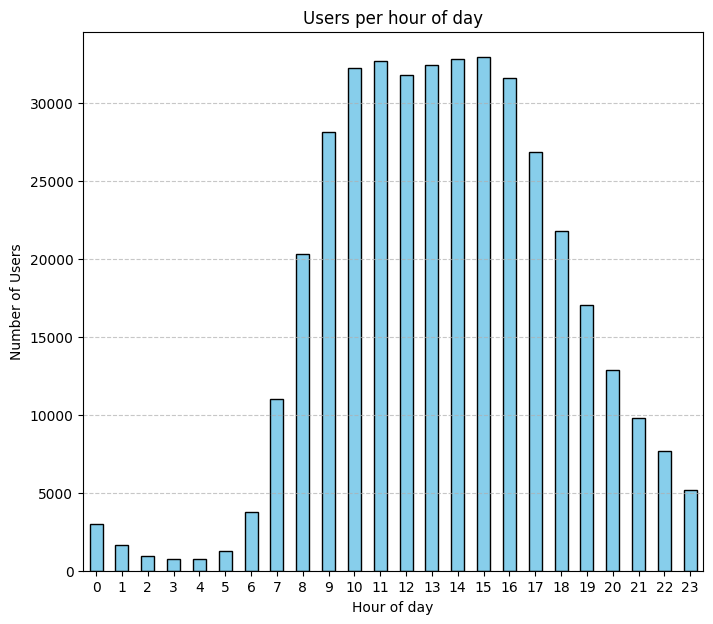

In [43]:
users_per_hour.plot(
    kind='bar',
    title='Users per hour of day',
    xlabel='Hour of day',
    ylabel='Number of Users',
    rot=0,
    color='skyblue', 
    edgecolor='black',
    figsize=(8, 7)
)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

- Hay una mayor cantidad de usuarios entre las **10:00 a.m. y las 4:00 p.m.**, esto quiere decir que estas horas son las horas pico de compras en la plataforma Instacart.
  
- Se observa que las horas valle se dan en las horas de la madrugada especificamente entre las **0:00 a.m. y las 6:00 a.m.**, lo que sugiere que durante estas horas hay una menor actividad por parte de los usuarios en la plataforma, probablemente debido a que la mayoría de los clientes están durmiendo.
  
- Se observa que desde las **7:00 a.m** hay un crecimiento constante en la cantidad de usuarios hasta llegar a las horas pico, lo que sugiere que los clientes comienzan a hacer sus compras a medida que avanza el día. 
  
-  A partir de las **5:00 p.m.** se observa una disminución gradual en la cantidad de usuarios, lo que sugiere que después de las horas pico, la actividad en la plataforma comienza a disminuir a medida que avanza la noche.

### [A3] ¿Qué día de la semana compran víveres las personas?

In [44]:
# Diccionario con el mapeo de los días de la semana
days_map = {0: 'Domingo', 1: 'Lunes', 2: 'Martes', 3: 'Miércoles', 4: 'Jueves', 5: 'Viernes', 6: 'Sábado'}

# Agrupo por días de la semana y hago conteo de usuarios unicos
orders_by_dow = df_instacart_orders.groupby(by='order_dow')['user_id'].nunique()
# Reemplazo los numeros por los nombres de los días
orders_by_dow.index = orders_by_dow.index.map(days_map)
orders_by_dow

order_dow
Domingo      57661
Lunes        56479
Martes       48587
Miércoles    45331
Jueves       44281
Viernes      46127
Sábado       45604
Name: user_id, dtype: int64

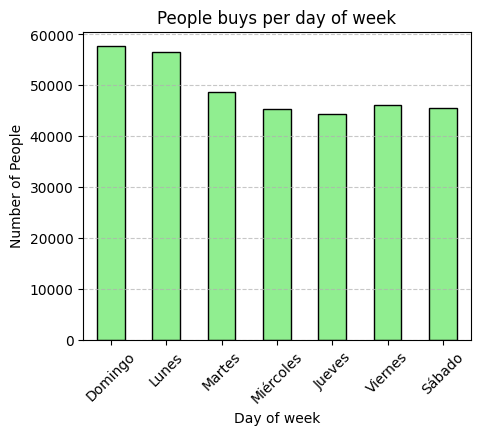

In [45]:
# Generación del grafico 
orders_by_dow.plot(
    kind='bar',
    title='People buys per day of week',
    xlabel='Day of week',
    ylabel='Number of People',
    rot=45,
    color='lightgreen', 
    edgecolor='black',
    figsize=(5, 4)
)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

- Se observa que todos los días de la semana hay actividad en la plataforma, pero existe una clara preferencia de los usuarios por realizar compras los días Domingo y Lunes.
  
- Los días con menor cantidad de compradores son los días miércoles (3) y el jueves (4), lo que sugiere que los clientes evitan hacer muchas compras en estos días.
  
- Los días martes, viernes y sabado tienen una cantidad de compradores muy cercana, lo que sugiere que en estos días los clientes tienen un comportamiento similar en cuanto a la frecuencia de sus compras.

### [A4] ¿Cuánto tiempo esperan las personas hasta hacer otro pedido? Comenta sobre los valores mínimos y máximos.

In [46]:
# Agrupo por "days_since_prior_order" y luego se cuenta cada uno de los valores con size()
days_wait = df_instacart_orders.groupby(by='days_since_prior_order').size()
days_wait

days_since_prior_order
0      9589
1     20179
2     27138
3     30224
4     31006
5     30096
6     33930
7     44577
8     25361
9     16753
10    13309
11    11467
12    10658
13    11737
14    13992
15     9416
16     6587
17     5498
18     4971
19     4939
20     5302
21     6448
22     4514
23     3337
24     3015
25     2711
26     2640
27     2986
28     3745
29     2673
30    51337
dtype: int64

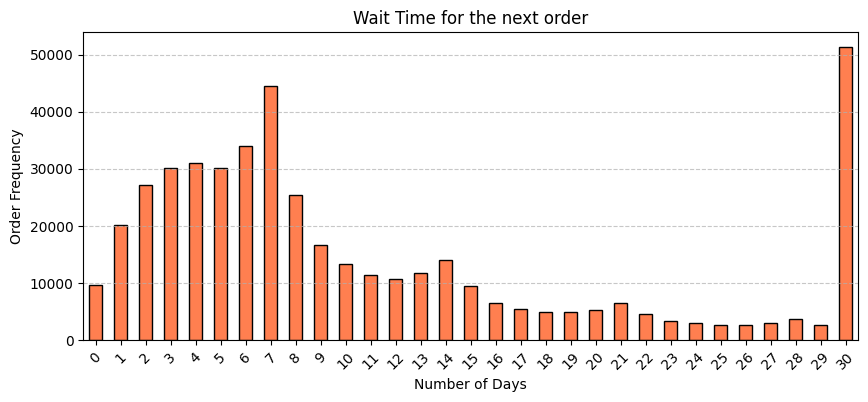

In [47]:
# Generación del grafico 
days_wait.plot(
    kind='bar',
    title='Wait Time for the next order',
    xlabel='Number of Days',
    ylabel='Order Frequency',
    rot=45,
    color='coral', 
    edgecolor='black',
    figsize=(10, 4)
)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

- El valor mínimo es **0 días**, lo que sugiere que algunos clientes podrían estar haciendo pedidos en el mismo día.
  
- Se observa que hay una cantidad significativa de usuarios que hacen su siguiente pedido a los **30 días** se considera el número máximo, lo que sugiere que muchos clientes podrían estar haciendo pedidos mensuales o que el sistema tiene un límite de 30 días para registrar el tiempo entre pedidos, lo que podría indicar que los clientes que esperan más de 30 días para hacer su siguiente pedido se registran como si hubieran esperado exactamente 30 días.
  
- Se observa que hay un pico cada **7 días (7, 14, 21, 28)**, lo que sugiere que algunos clientes podrían estar haciendo pedidos semanales. Siendo evidente que existe una recurrencia semanal en el comportamiento de compra de algunos clientes.

# [B] Intermedio (deben completarse todos para aprobar)

1. ¿Existe alguna diferencia entre las distribuciones `'order_hour_of_day'` de los miércoles y los sábados? Traza gráficos de barra de `'order_hour_of_day'` para ambos días en la misma figura y describe las diferencias que observes.
2. Grafica la distribución para el número de órdenes que hacen los clientes (es decir, cuántos clientes hicieron solo 1 pedido, cuántos hicieron 2, cuántos 3, y así sucesivamente...).
3. ¿Cuáles son los 20 principales productos que se piden con más frecuencia (muestra su identificación y nombre)?

### [B1] Diferencia entre miércoles y sábados para  `'order_hour_of_day'`. Traza gráficos de barra para los dos días y describe las diferencias que veas.

In [48]:
# Ordenes por dia
df_wed_orders = df_instacart_orders[df_instacart_orders['order_dow'] == 3]
df_sat_orders = df_instacart_orders[df_instacart_orders['order_dow'] == 6]

# Conteo de registros:
print(f"Cantidad de registros para el miercoles: {len(df_wed_orders)}")
print(f"Cantidad de registros para el sabado: {len(df_sat_orders)}")

Cantidad de registros para el miercoles: 60897
Cantidad de registros para el sabado: 62649


In [49]:
# Agrupo ordenes unicas por hora del día
group_wed_orders = df_wed_orders.groupby(by='order_hour_of_day')['order_id'].nunique()
group_wed_orders.name = 'wednesday'
group_sat_orders = df_sat_orders.groupby(by='order_hour_of_day')['order_id'].nunique()
group_sat_orders.name = 'saturday'

# Conteo de registros (debe ser el mismo 24)
print(f"Cantidad de registros para el miercoles: {len(group_wed_orders)}")
print(f"Cantidad de registros para el sabado: {len(group_sat_orders)}")

Cantidad de registros para el miercoles: 24
Cantidad de registros para el sabado: 24


In [50]:
# Se unen las dos series en en un solo dataframe
df_ws_orders = pd.concat([group_wed_orders, group_sat_orders], axis=1)
df_ws_orders = df_ws_orders.reset_index()
df_ws_orders

,order_hour_of_day,wednesday,saturday
0,0,373,464
1,1,215,254
2,2,106,177
3,3,101,125
4,4,108,118
5,5,170,161
6,6,643,451
7,7,1732,1619
8,8,3125,3246
9,9,4490,4311


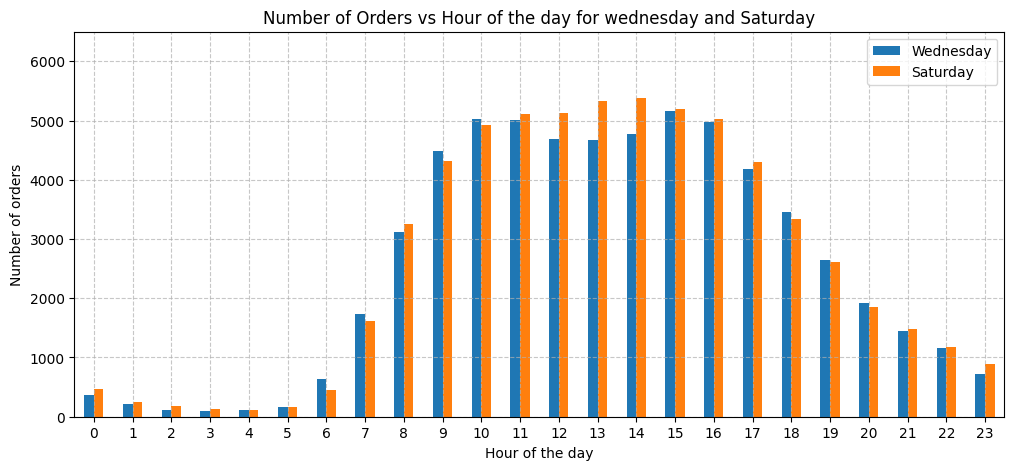

In [52]:
df_ws_orders.plot(
    x='order_hour_of_day',
    kind='bar',
    title='Number of Orders vs Hour of the day for wednesday and Saturday',
    xlabel='Hour of the day',
    ylabel='Number of orders',
    ylim=[0, 6500],
    figsize=(12, 5),
    rot=0
)

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.legend(['Wednesday', 'Saturday'])
plt.show()

Se realizó el análisis solicitado, el cual para este caso se filtraron los datos del dataframe `df_instacart_orders` para obtener dos subconjuntos: uno para los miércoles (**order_dow == 3**) y otro para los sábados (**order_dow == 6**). Posteriormente, se agruparon ambos subconjuntos por la columna `order_hour_of_day` y se utilizó el método `nunique()` para obtener la cantidad de ordenes únicas realizadas por hora del día para cada uno de los días. Finalmente, se trazaron gráficos de barra para ambos días en la misma figura para comparar las distribuciones. De acuerdo con los resultados se puede concluir lo siguiente:

- Los dos días poseen una distribución similar en cuanto a las horas del día en que se hacen los pedidos, lo que sugiere que los clientes tienen patrones de compra similares tanto los miércoles como los sábados. Sin embargo, se observa que los sábados hay una mayor cantidad de pedidos en las horas pico (**entre las 10:00 a.m. y las 4:00 p.m.**) en comparación con los miércoles, lo que sugiere que los clientes podrían estar haciendo más compras durante el fin de semana.
- Para el día miércoles se observa una mayor cantidad de pedidos en las horas de la mañana (**entre las 6:00 a.m. y las 9:00 a.m.**) en comparación con los sábados, lo que sugiere que algunos clientes podrían estar haciendo sus compras al inicio del día durante la semana laboral.
- El máximo en cantidad de pedidos para los miércoles ocurre a las **3:00 p.m.**, mientras que para los sábados el máximo ocurre a las **2:00 p.m.**, lo que supone que los clientes podrían estar haciendo sus compras un poco más temprano durante el fin de semana en comparación con los días de semana.
- Se observa que para el día sábado hay una mayor cantidad de pedidos en las horas que comprenden el intervalor entre las **11:00 a.m. y las 5:00 p.m.**, lo que sugiere que durante el fin de semana los clientes podrían estar haciendo más compras durante el mediodía y la tarde en comparación al día miércoles.
- Para el día miércoles se observa una mayor cantidad de pedidos entre las **6:00 p.m. y las 8:00 p.m.** en comparación con los sábados, lo que sugiere que algunos clientes podrían estar haciendo sus compras al final del día.
- Finalmente, se observa que para el día miércoles hay dos picos en la cantidad de pedidos, uno se observa en horas de la mañana (**entre las 10:00 a.m. y las 11:00 a.m.**) y otro se observa en horas de la tarde (**a las 3:00 p.m.**), mientras que para el día sábado hay un solo pico en la cantidad de pedidos que ocurre durante las primeras horas de la tarde (**entre la 1:00 p.m. y las 2:00 p.m.**). Lo cual sugiere que para el fin de semana los clientes podrian estar haciendo sus compras para el almuerzo, mientras que para el día miércoles los clientes podrían estar haciendo sus compras tanto para el almuerzo como un snack.

### [B2] ¿Cuál es la distribución para el número de pedidos por cliente?

In [53]:
# Agrupacion de df_instacart_orders por user_id y se escoge las order_id unicas
orders_by_user = df_instacart_orders.groupby(by='user_id')['order_id'].nunique()

# Se calcula la distribucion de ordenes por usuario utilizando el metodo value_counts()
distribution = orders_by_user.value_counts().sort_index()
distribution

order_id
1     55357
2     36508
3     21547
4     13498
5      8777
6      6012
7      4240
8      3019
9      2152
10     1645
11     1308
12      947
13      703
14      512
15      437
16      263
17      184
18      121
19       85
20       52
21       22
22       23
23       19
24        3
25        1
26        1
28        1
Name: count, dtype: int64

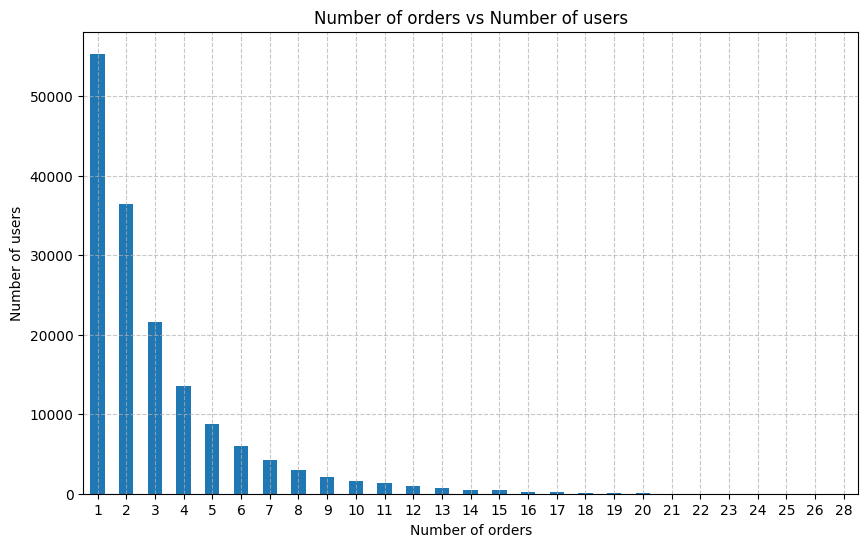

In [61]:
# Grafico de Barras
distribution.plot(
    kind='bar',
    title='Number of orders vs Number of users',
    xlabel='Number of orders',
    ylabel='Number of users',
    rot=0,
    figsize=(10,6)
)

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

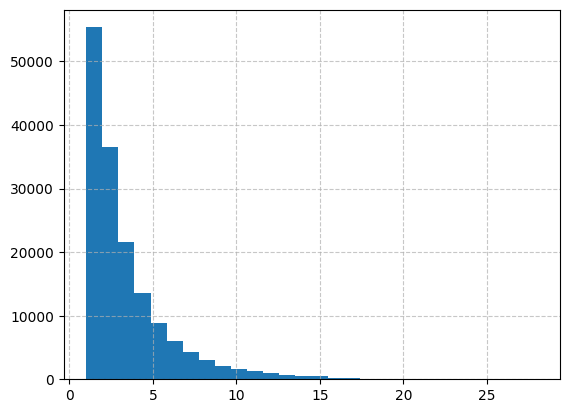

In [62]:
# Equivalente y quizas mas apropiado para distribuciones un grafico de tipo histograma
orders_by_user.hist(
    bins=28
)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

Se realizó el análisis solicitado, para este caso se agruparon los datos del dataframe `df_instacart_orders` por la columna `user_id` y se referenció la columna `order_id` para luego obtener el conteo de pedidos por cliente utilizando el método `nunique()` para obtener los ids unicos de cada pedido. Posteriormente, se trazó un histograma para visualizar la distribución del número de pedidos por cliente. De acuerdo con los resultados se puede concluir lo siguiente:

- La mayoría de los clientes hicieron **entre 1 y 10 pedidos**, lo que sugiere que la mayoría de los clientes son compradores ocasionales o regulares con una frecuencia moderada de compras.
- Hay una cantidad significativa de clientes que hicieron solo **1 pedido**, lo que sugiere que hay muchos clientes que podrían estar probando la plataforma por primera vez o que no han encontrado suficiente valor para hacer pedidos adicionales.
- Se oserva que hay muy pocos clientes que hicieron **más de 20 pedidos**, lo que sugiere que hay una pequeña cantidad de clientes muy frecuentes o leales a la plataforma.
- La distribución muestra una tendencia decreciente a medida que aumenta el número de pedidos, lo que sugiere que a medida que los clientes hacen más pedidos, es menos probable que continúen haciendo pedidos adicionales.

### [B3] ¿Cuáles son los 20 productos más populares (muestra su ID y nombre)?

In [56]:
# Se selecciona la columna product_id del dataframe df_order_products y se hace un conteo
quantity_by_product = df_order_products['product_id'].value_counts()

# La serie resultante lo convertimos nuevamente a Dataframe
df_top_prod = pd.DataFrame(quantity_by_product).reset_index()
df_top_prod.columns = ['product_id', 'count'] # Aseguro que el orden y nombre de las columnas se el correcto
df_top_prod = df_top_prod.loc[0:19, :] # Escojo los 20 primeros productos
df_top_prod

,product_id,count
0,24852,66050
1,13176,53297
2,21137,37039
3,21903,33971
4,47209,29773
5,47766,24689
6,47626,21495
7,16797,20018
8,26209,19690
9,27845,19600


In [57]:
# se realiza el merge con el dataframe df_products para obtener el nombre de los productos
df_final_top_20 = df_top_prod.merge(df_products, on='product_id')
df_final_top_20 = df_final_top_20[['product_id', 'product_name']]
df_final_top_20

,product_id,product_name
0,24852,Banana
1,13176,Bag of Organic Bananas
2,21137,Organic Strawberries
3,21903,Organic Baby Spinach
4,47209,Organic Hass Avocado
5,47766,Organic Avocado
6,47626,Large Lemon
7,16797,Strawberries
8,26209,Limes
9,27845,Organic Whole Milk


Se realizó el análisis solicitado, el cual para este casi fue necesario utilizar el dataframe `df_order_products` para obtener la cantidad de veces que se pidió cada producto utilizando la columna `product_id` y el método `value_counts()`. Posteriormente, se seleccionaron los 20 productos más populares y se realizó un merge con el dataframe `df_products` para obtener el nombre de cada producto. De acuerdo con los resultados se puede concluir lo siguiente:

- El producto más popular es la "**Banana**", por lo tanto, se puede inferir que es un producto básico y comúnmente comprado por los clientes en la plataforma Instacart.
- La mayoria de los productos más populares son frutas y verduras, lo que sugiere que los clientes de Instacart tienen una preferencia por productos frescos y saludables.
- Se observa que algunos productos populares son productos organicos, lo que sugiere que hay una demanda significativa por productos orgánicos entre los clientes de Instacart.

# [C] Difícil (deben completarse todos para aprobar)

1. ¿Cuántos artículos suelen comprar las personas en un pedido? ¿Cómo es la distribución?
2. ¿Cuáles son los 20 principales artículos que vuelven a pedirse con mayor frecuencia (muestra sus nombres e IDs de los productos)?
3. Para cada producto, ¿cuál es la tasa de repetición del pedido (número de repeticiones de pedido/total de pedidos?
4. Para cada cliente, ¿qué proporción de los productos que pidió ya los había pedido? Calcula la tasa de repetición de pedido para cada usuario en lugar de para cada producto.
5. ¿Cuáles son los 20 principales artículos que la gente pone primero en sus carritos (muestra las IDs de los productos, sus nombres, y el número de veces en que fueron el primer artículo en añadirse al carrito)?

### [C1] ¿Cuántos artículos compran normalmente las personas en un pedido? ¿Cómo es la distribución?

In [58]:
# Agrupo por "order_id" y selecciono los "product_id" para luego contarlos
prod_by_order = df_order_products.groupby(by="order_id")['product_id'].count()
prod_by_order

order_id
4          13
9          15
11          5
19          3
20          8
           ..
3421034    17
3421053     9
3421071     5
3421077     4
3421079     1
Name: product_id, Length: 450046, dtype: int64

In [60]:
# Obtengo las caracteristicas principales de la serie
prod_by_order.describe()

count    450046.000000
mean         10.098983
std           7.540206
min           1.000000
25%           5.000000
50%           8.000000
75%          14.000000
max         127.000000
Name: product_id, dtype: float64

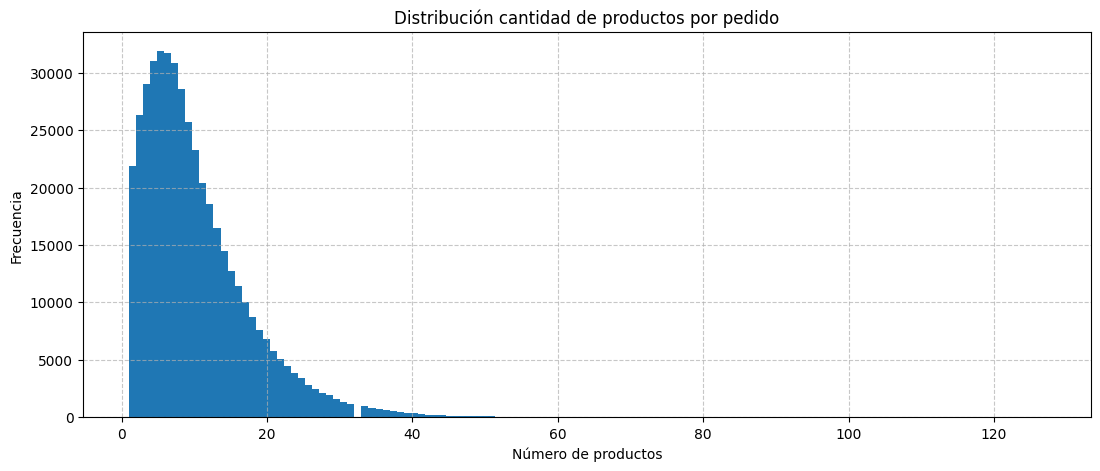

In [63]:
# Represento los datos mediante un histograma
prod_by_order.hist(bins=130, figsize=(13, 5))
plt.title('Distribución cantidad de productos por pedido')
plt.xlabel('Número de productos')
plt.ylabel('Frecuencia')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

Para realizar el análisis solicitado, se utilizó el dataframe `df_order_products` agrupandolo por la columna `order_id` y tomando como referencia la columna `product_id`, luego se utilizó el método `count()`, de esta manera se obtuvo la cantidad de artículos por pedido. Posteriormente, se trazó un histograma para visualizar la distribución de la cantidad de artículos por pedido. De acuerdo con los resultados se puede concluir lo siguiente:

- Se observa que la mayoría de los pedidos contienen **entre 1 y 10 artículos**, lo que sugiere que los clientes suelen hacer pedidos con una cantidad moderada de productos.
- Se observa que se tiene una distribución decreciente a medida que aumenta la cantidad de artículos por pedido, lo que sugiere que las compras en la plataforma Instacart tienden a ser de menor volumen, con una menor cantidad de pedidos que contienen una gran cantidad de artículos.
- El promedio de articulos por pedido es de aproximadamente 10, lo que sugiere que los clientes suelen hacer pedidos con esta cantidad de productos.
- Se observa que hay algunos pedidos que contienen una cantidad muy alta de artículos (más de 20), lo que sugiere que algunos clientes podrían estar haciendo pedidos para abastecerse de víveres para un período prolongado o para eventos especiales.

### [C2] ¿Cuáles son los 20 principales artículos que vuelven a pedirse con mayor frecuencia (muestra sus nombres e IDs de los productos)?

In [64]:
df_prod_reordered = df_order_products.query("reordered == 1")   # Filtrado de datos con reordered == 1
prod_reordered = df_prod_reordered['product_id'].value_counts() # Agrupación y conteo por product_id
prod_reordered 

product_id
24852    55763
13176    44450
21137    28639
21903    26233
47209    23629
         ...  
33506        1
27878        1
31751        1
24384        1
47673        1
Name: count, Length: 36228, dtype: int64

In [65]:
top_20_prod_reordered = prod_reordered.head(20).reset_index() # Se selecciona el top 20 y se resetean los idices
top_20_prod_reordered.columns = ['product_id', 'count'] # Se renombran las columnas
top_20_prod_reordered

,product_id,count
0,24852,55763
1,13176,44450
2,21137,28639
3,21903,26233
4,47209,23629
5,47766,18743
6,27845,16251
7,47626,15044
8,27966,14748
9,16797,13945


In [66]:
# Se realiza el cruce con products para obtener el nombre de los productos
df_final_top_20 = top_20_prod_reordered.merge(df_products, on='product_id') 
df_final_top_20[['product_id', 'product_name']]

,product_id,product_name
0,24852,Banana
1,13176,Bag of Organic Bananas
2,21137,Organic Strawberries
3,21903,Organic Baby Spinach
4,47209,Organic Hass Avocado
5,47766,Organic Avocado
6,27845,Organic Whole Milk
7,47626,Large Lemon
8,27966,Organic Raspberries
9,16797,Strawberries


Se realizó el análisis solicitado, para este caso se filtraron los datos del dataframe `df_order_products` para obtener solo los registros donde la columna `reordered` es igual a 1, lo que indica que el producto fue pedido nuevamente. Posteriormente, se toma la columna `product_id` y se hace un conteo de estos productos por medio del método `value_counts()`. Luego, se seleccionaron los 20 productos con mayor cantidad de pedidos repetidos y se realizó un merge con el dataframe `df_products` para obtener el nombre de cada producto. De acuerdo con los resultados se puede concluir lo siguiente:

- Se observa que el producto con mayor cantidad de pedidos repetidos es la "**Banana**", lo que sugiere que es un producto básico y comúnmente comprado por los clientes en la plataforma Instacart, y que los clientes tienden a volver a comprarlo con frecuencia.
- La mayoría de los productos con mayor cantidad de pedidos repetidos son frutas y verduras, lo que sugiere que los clientes de Instacart tienen una preferencia por productos frescos y saludables.
- Se observa que algunos productos con alta cantidad de pedidos repetidos son productos orgánicos, lo que sugiere que hay una demanda significativa por productos orgánicos entre los clientes de Instacart, y que existe una tyendencia a volver a comprar estos productos con frecuencia.

### [C3] Para cada producto, ¿cuál es la proporción de las veces que se pide y que se vuelve a pedir?

In [68]:
# Conteo total de productos pedidos
prod_total_ord = df_order_products.groupby('product_id').size().reset_index(name='total_prod_pedidos')
prod_total_ord

,product_id,total_prod_pedidos
0,1,280
1,2,11
2,3,42
3,4,49
4,7,2
...,...,...
45568,49690,5
45569,49691,72
45570,49692,12
45571,49693,25


In [69]:
# Conteo de productos reordenados o que se pidieron nuevamente
prod_reorder = df_order_products.query("reordered == 1").groupby('product_id').size().reset_index(name='prod_recomprados')
prod_reorder

,product_id,prod_recomprados
0,1,158
1,3,31
2,4,25
3,7,1
4,8,6
...,...,...
36223,49690,4
36224,49691,31
36225,49692,5
36226,49693,11


In [76]:
# Hago un join de los dataframes prod_total_ord y prod_reorder
# Tipo de join left para mantener todos los productos
df_proporciones = prod_total_ord.merge(prod_reorder, on='product_id', how="left") 

# Se reemplazan los Nan en la columna "prod_recomprados" con cero porque son productos que no fueron recomprados
# Por lo tanto cuando se calcule la proporcion sera de un 0%
df_proporciones['prod_recomprados'] = df_proporciones['prod_recomprados'].fillna(0).astype("int")

# Calculo de la proporcion real
df_proporciones['proporcion_recompra'] = df_proporciones['prod_recomprados']/df_proporciones['total_prod_pedidos']
df_proporciones

,product_id,total_prod_pedidos,prod_recomprados,proporcion_recompra
0,1,280,158,0.564286
1,2,11,0,0.000000
2,3,42,31,0.738095
3,4,49,25,0.510204
4,7,2,1,0.500000
...,...,...,...,...
45568,49690,5,4,0.800000
45569,49691,72,31,0.430556
45570,49692,12,5,0.416667
45571,49693,25,11,0.440000


In [ ]:
# Hago el join con el df_products para obtener el nombre de los productos
df_proporciones_final = df_proporciones.merge(df_products, on='product_id')

# Presento los campos necesarios para analisis
df_proporciones_final[['product_id', 'product_name', 'proporcion_recompra']]

,product_id,product_name,proporcion_recompra
0,1,Chocolate Sandwich Cookies,0.564286
1,2,All-Seasons Salt,0.000000
2,3,Robust Golden Unsweetened Oolong Tea,0.738095
3,4,Smart Ones Classic Favorites Mini Rigatoni Wit...,0.510204
4,7,Pure Coconut Water With Orange,0.500000
...,...,...,...
45568,49690,HIGH PERFORMANCE ENERGY DRINK,0.800000
45569,49691,ORIGINAL PANCAKE & WAFFLE MIX,0.430556
45570,49692,ORGANIC INSTANT OATMEAL LIGHT MAPLE BROWN SUGAR,0.416667
45571,49693,SPRING WATER BODY WASH,0.440000


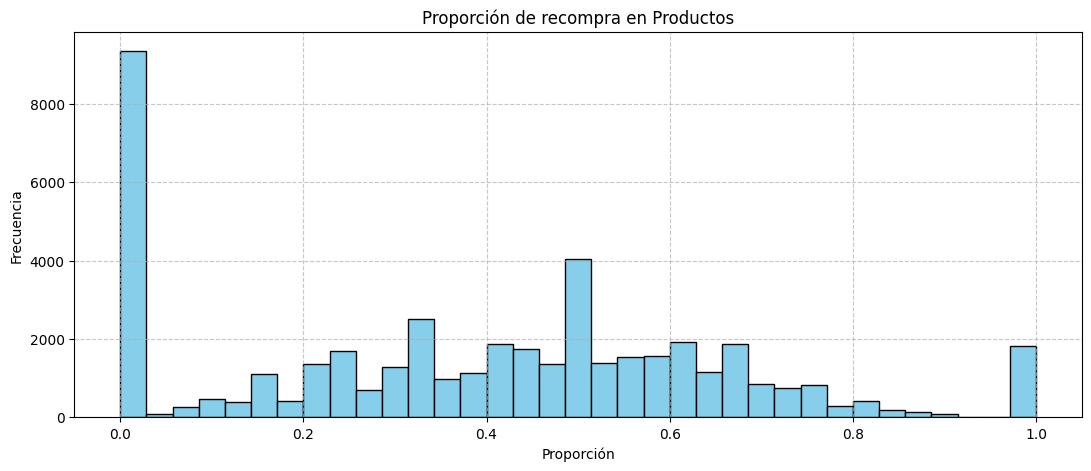

In [ ]:
# Generacion del grafico de tipo histograma
df_proporciones_final['proporcion_recompra'].hist(bins=35, figsize=(13,5), color='skyblue', edgecolor='black')
plt.title('Proporción de recompra por Producto')
plt.xlabel('Proporción')
plt.ylabel('Frecuencia')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

Se realizó el análisis para calcular la proporción de recompra de los productos, para este caso se utilizó el dataframe `df_order_products`. En primer lugar, se halla la cantidad total de cada producto agrupando los datos por la columna `product_id` y utilizando el método `size()` para hacer un conteo, finalmente se resetea el indice para que quede como una tabla. Luego, se calculó el total de productos que se recompraron, para este caso se filtra el dataframe para obtener solo los registros donde la columna `reordered` es igual a 1, lo que indica que el producto fue pedido nuevamente, y se agrupa por la columna `product_id` utilizando el método `size()` para el conteo nuevamente y se resetea el índice. Como siguiente paso, se realiza un merge entre ambas tablas utilizando la columna `product_id` como referencia para obtener una tabla con el total de pedidos y el total de pedidos repetidos por producto. Finalmente, se calcula la proporción de recompra dividiendo el total de pedidos repetidos entre el total de pedidos para cada producto.

Es importante recalcar que se asigno una proporción de recompra de 0 para los productos que no tienen registros de pedidos repetidos, esto se hizo para evitar valores nulos en la columna de proporción de recompra y para reflejar correctamente que estos productos no fueron recomprados.

De acuerdo con los resultados se puede concluir lo siguiente:

- Los productos que tienen **una proporción mayor a 0.5** son aquellos que se piden y se vuelven a pedir con mayor frecuencia, lo que sugiere que estos productos son altamente valorados por los clientes y tienen una alta tasa de satisfacción.
- Los productos con una **proporción de recompra menor a 0.5** son aquellos que se piden pero no se vuelven a pedir con tanta frecuencia, lo que sugiere que estos productos podrían no ser tan populares o podrían no cumplir con las expectativas de los clientes.
- Hay una gran cantidad de productos con **una proporción de recompra cercana a 0**, lo que sugiere que muchos productos son pedidos solo una vez y no se vuelven a pedir, lo que podría indicar que estos productos son de uso único o que los clientes no encuentran suficiente valor para volver a comprarlos.
- Hay algunos productos con **una proporción de recompra igual a 1**, lo que sugiere que estos productos son pedidos exclusivamente por clientes que los vuelven a comprar, lo que podría indicar que estos productos son esenciales para los clientes o que tienen una alta calidad y satisfacción.

### [C4] Para cada cliente, ¿qué proporción de sus productos ya los había pedido?

In [80]:
# Hago un join entre "df_order_products" y "df_instacart" para traer el user_id por cada order_id
# Manteniendo el campo "reordered" del dataset "df_order_products"
df_orders_users_products = df_order_products.merge(df_instacart_orders[['user_id', 'order_id']], on='order_id')

# Agrupamos por "user_id" y seleccionamos la columna "reordered"
# Se calcula el promedio con mean() obteniendo de esta manera la proporción de productos recomprados por cliente
df_prop = df_orders_users_products.groupby('user_id')['reordered'].mean().reset_index(name='prop_prod_recomprados')
df_prop

,user_id,prop_prod_recomprados
0,2,0.038462
1,4,0.000000
2,5,0.666667
3,6,0.000000
4,7,0.928571
...,...,...
149621,206203,0.222222
149622,206206,0.714286
149623,206207,0.891304
149624,206208,0.696000


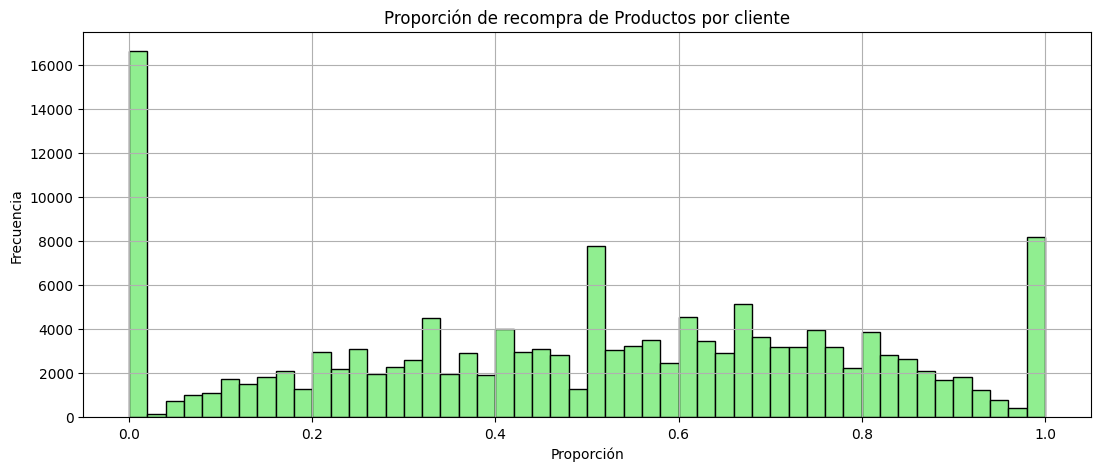

In [81]:
# Representación gráfica
df_prop['prop_prod_recomprados'].hist(bins=50, figsize=(13,5), color='lightgreen', edgecolor='black')
plt.title('Proporción de recompra de Productos por cliente')
plt.xlabel('Proporción')
plt.ylabel('Frecuencia')
plt.show()

Para realizar el análisis para calcular la proporción de recompra de productos por cliente, fue necesario revisar que valores contenia la columna `reordered` del dataframe `df_order_products` los cuales contiene 0 para productos que no fueron pedidos nuevamente y 1 para productos que si fueron pedidos nuevamente, por lo tanto, se utilizó esta columna como referencia. por otro lado, se identificó que era  necesario un dataset que contuviera el campo `user_id` y a su vez el campo `order_id` para poder relacionar los pedidos con los clientes, por lo tanto, se utilizó el dataframe `df_instacart_orders` para obtener esta información. Teniendo esto claro, se procede a realizar un merge de los dataframes `df_order_products` y `df_instacart_orders` utilizando la columna `order_id` como referencia, luego se procede a agrupar por cliente utilizando la columna `user_id` y se calcula la proporción de recompra dividiendo la suma de la columna `reordered` entre el conteo total de productos pedidos por cada cliente que esto se traduce al calculo del promedio de la columna `reordered` para cada cliente utilizando el método `mean()`. Finalmente, se resetea el índice para obtener una tabla con el `user_id` y la proporción de recompra por cliente. De este analisis se puede concluir lo siguiente:

- Se observa que hay una gran cantidad de clientes con una proporción de recompra cercana a 0, lo que sugiere que muchos clientes hacen pedidos ocasionales o no encuentran suficiente valor para volver a comprar los mismos productos.
- Tambien se observa que hay una cantidad significativa de clientes con proporciones de recompra cercanas a 1, lo que sugiere que estos clientes recompran gran parte de los productos que han pedido.
- Se observa que hay una distribución variada de proporciones de recompra entre los clientes, lo que sugiere que hay diferentes tipos de clientes en la plataforma, algunos con alta lealtad y otros con baja lealtad.
- Adicionalmente hay una cantidad de clientes significativa que poseen una recompra cercana al 0.5, lo que sugiere que la mitad de los productos que piden estos clientes son productos que han pedido anteriormente, lo que podría indicar que estos clientes tienen una mezcla de productos favoritos y productos nuevos en sus pedidos.

### [C5] ¿Cuáles son los 20 principales artículos que las personas ponen primero en sus carritos?

In [84]:
# Filtrado de productos que ponen de primeras en el carrito de compra
df_first_prod_car = df_order_products.query("add_to_cart_order == 1")

# Agrupo por "product_id" y hago el conteo, para luego ordenarlos de manera descendiente
df_first_prod_car = df_first_prod_car.groupby('product_id').size().sort_values(ascending=False).reset_index(name='primer_prod_carrito')
df_first_prod_car

,product_id,primer_prod_carrito
0,24852,15562
1,13176,11026
2,27845,4363
3,21137,3946
4,47209,3390
...,...,...
26755,43,1
26756,41,1
26757,33,1
26758,21942,1


In [86]:
# Elijo los 20 primeros
df_first_prod_car_top_20 = df_first_prod_car.head(20)

# Obtengo los nombres de cada producto haciendo un join
df_first_prod_car_top_20_name = df_first_prod_car_top_20.merge(df_products, on='product_id')
df_first_prod_car_top_20_name[['product_id', 'product_name']]

,product_id,product_name
0,24852,Banana
1,13176,Bag of Organic Bananas
2,27845,Organic Whole Milk
3,21137,Organic Strawberries
4,47209,Organic Hass Avocado
5,21903,Organic Baby Spinach
6,47766,Organic Avocado
7,19660,Spring Water
8,16797,Strawberries
9,27966,Organic Raspberries


Para este análisis se utilizó el dataframe `df_order_products` para identificar los productos que las personas ponen primero en sus carritos. En primer lugar, se filtraron los datos para obtener solo los registros donde la columna `add_to_cart_order` es igual a 1, lo que indica que el producto fue el primer artículo añadido al carrito. Luego, se tomó la columna `product_id` y se hizo un conteo de estos productos utilizando el método `size()` y se ordeno de manera descendente. Finalmente, se seleccionaron los 20 productos más populares y se realizó un merge con el dataframe `df_products` para obtener el nombre de cada producto. De acuerdo con los resultados se puede concluir lo siguiente:

- El producto más comúnmente añadido primero al carrito es la "**Banana**", lo que sugiere que es un producto básico y comúnmente comprado por los clientes en la plataforma Instacart, y que los clientes tienden a añadirlo al carrito como el primer artículo.
- El top 20 en su gran mayoria esta compuesto por frutas y verduras, lo que sugiere que los clientes de Instacart tienen una preferencia por productos frescos y saludables, y que tienden a añadir estos productos al carrito como los primeros artículos.
- Se observa que algunos productos populares que se añaden primero al carrito son productos orgánicos, esto sugiere que los clientes de Instacart valoran los productos orgánicos y tienden a añadirlos al carrito como los primeros artículos, lo que podría indicar una preferencia por productos orgánicos entre los clientes de la plataforma.

### Conclusion general del proyecto:

como conclusiones generales tenemos las siguientes:

PASO 1 - PASO 2:
- Se abordaron valores ausentes en las columnas `days_since_prior_order` (tratados como primer pedidos) y `add_to_cart_order` (imputados con el valor marcador 999) de los dataframes `df_orders` y `df_order_products` respectivamente. Estas decisiones fueron fundamentales para preservar la integridad de los datos y permitir un análisis correcto sin introducir sesgos significativos.
- Se identificaron y manejaron valores duplicados en la columna `product_name` del dataframe `df_products`, reemplazando los valores ausentes por "Unknown" para mantener la consistencia de los datos y evitar la pérdida de información relevante.
- Se validó la integridad de los dataframes `df_departments` y `df_aisles`, confirmando que no existen registros duplicados ni IDs repetidos, lo que permitió mantener la estructura original de los datos sin necesidad de transformaciones adicionales.
- Se optimizó el uso de memoria al convertir la columna `add_to_cart_order` de tipo `float64` a `int64` después de imputar los valores ausentes, lo que mejoró la eficiencia del análisis sin perder precisión en los datos.
- Se verificó que los valores en las columnas `order_hour_of_day` y `order_dow` del dataframe `df_instacart_orders` son razonables, con `order_hour_of_day` oscilando entre 0 y 23, y `order_dow` oscilando entre 0 y 6, lo que confirma la consistencia de los datos en estas columnas.


PASO 3:
- Se identificaron patrones de compra en función de la hora del día y el día de la semana, con picos de actividad entre las 10:00 a.m. y las 4:00 p.m., y una mayor cantidad de compradores los domingos y lunes.
- Se observó que existen picos de compras cada 7 días, lo que sugiere que algunos clientes podrían estar haciendo pedidos semanales. Adicionalmente, hay mayor cantidad de compras los primeros 7 días del mes y una disminución gradual a medida que avanza el mes. Por ultimo, hay un pico considerable en compras en el día 30 de cada mes.
- Se identificó que la mayoria de clientes realizan entre 1 y 10 pedidos, con una gran cantidad de clientes que hacen solo 1 pedido, lo que sugiere que muchos clientes son compradores ocasionales o están probando la plataforma por primera vez.
- Los productos más populares son frutas y verduras, con la "Banana" como el producto más pedido y el más repetido, lo que sugiere una preferencia por productos frescos y saludables entre los clientes de Instacart.
- Se observó que algunos productos tienen una alta tasa de recompra, lo que sugiere que estos productos son altamente valorados por los clientes y tienen una alta tasa de satisfacción. Sin embargo, existe una distribución clara de "una sola compra", lo que permite segmentar los productos entre aquellos que son de uso único y aquellos que son productos favoritos o esenciales para los clientes.
- Se identificó que hay una gran cantidad de clientes con una proporción de recompra cercana a 0, lo que sugiere que muchos clientes hacen pedidos ocasionales o no encuentran suficiente valor para volver a comprar los mismos productos. Por otro lado, también se observó que hay una cantidad significativa de clientes con proporciones de recompra cercanas a 1, lo que sugiere que estos clientes recompran gran parte de los productos que han pedido, lo que indica una alta lealtad hacia la plataforma.
- Por ultimo se identifico que la mayoría de los productos que las personas ponen primero en sus carritos son frutas y verduras, con la "Banana" como el producto más comúnmente añadido primero al carrito, lo que sugiere que los clientes de Instacart valoran los productos frescos y saludables, y tienden a añadir estos productos al carrito como los primeros artículos. 